In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import koreanize_matplotlib

In [2]:
df = pd.read_csv("/Users/youngjinseo/Desktop/데이터분석프로젝트/retail_store_inventory.csv")
df.head(4)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn


In [3]:
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  str    
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  str    
dtypes: float64(3), int64(5), str(7)
memory usage: 8.4 MB


In [5]:
df['Date'] = pd.to_datetime(df['Date'])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                73100 non-null  datetime64[us]
 1   Store ID            73100 non-null  str           
 2   Product ID          73100 non-null  str           
 3   Category            73100 non-null  str           
 4   Region              73100 non-null  str           
 5   Inventory Level     73100 non-null  int64         
 6   Units Sold          73100 non-null  int64         
 7   Units Ordered       73100 non-null  int64         
 8   Demand Forecast     73100 non-null  float64       
 9   Price               73100 non-null  float64       
 10  Discount            73100 non-null  int64         
 11  Weather Condition   73100 non-null  str           
 12  Holiday/Promotion   73100 non-null  int64         
 13  Competitor Pricing  73100 non-null  float64       
 14  S

# 데이터 시각화

## 날짜별 판매량 추이

In [7]:
mf = df.groupby('Date').agg(TotalSold= ('Units Sold','sum')).reset_index()
mf

,Date,TotalSold
0,2022-01-01,14484
1,2022-01-02,13415
2,2022-01-03,13681
3,2022-01-04,14084
4,2022-01-05,12572
...,...,...
726,2023-12-28,16271
727,2023-12-29,13368
728,2023-12-30,13156
729,2023-12-31,11208


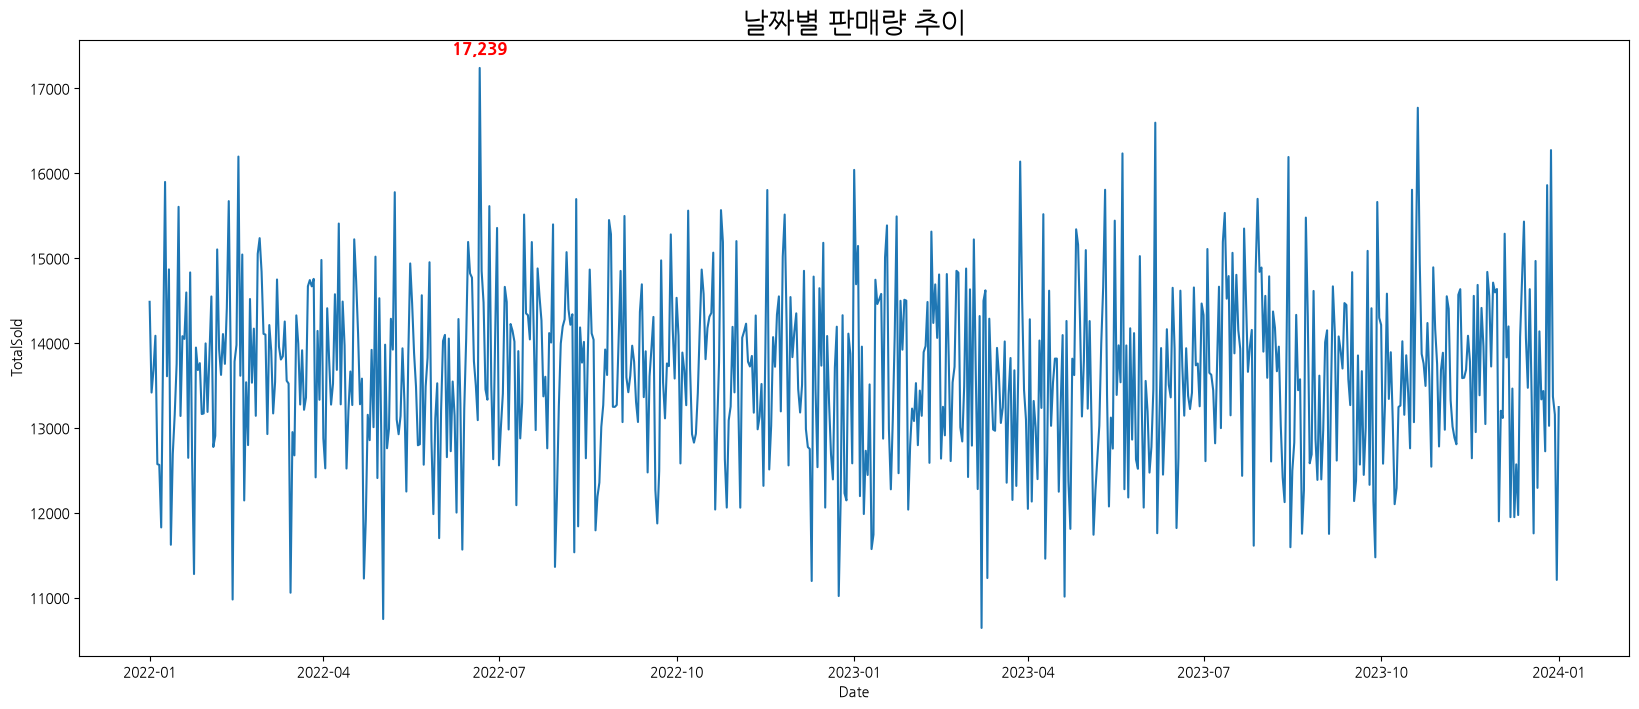

In [8]:
plt.figure(figsize = (20,8))

max_idx = mf['TotalSold'].idxmax()
max_date = mf.loc[max_idx, 'Date']
max_price = mf.loc[max_idx, 'TotalSold']


sns.lineplot(data = mf , x = 'Date', y = 'TotalSold')

plt.annotate(
    f'{max_price:,.0f}',
    xy=(max_date, max_price),
    xytext=(0, 10),
    textcoords='offset points',
    ha='center',
    fontsize=12,
    fontweight='bold',
    color='red'
)

plt.title('날짜별 판매량 추이',fontsize = 20)

plt.show()

## 재고 수준과 판매량의 관계 

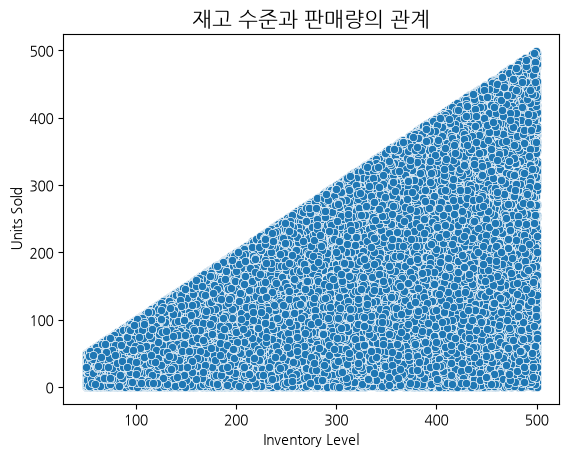

In [9]:
sns.scatterplot(data = df, x = 'Inventory Level', y = 'Units Sold')
plt.title('재고 수준과 판매량의 관계', fontsize = 15)
plt.show()

## 지역 x 카테고리 판매 성과 

In [10]:
pivot = df.pivot_table(index = 'Category', columns = 'Region', values = 'Price',aggfunc = 'mean')
pivot

Region,East,North,South,West
Category,,,,
Clothing,54.900986,55.470224,54.576385,54.621199
Electronics,55.087533,55.204492,55.464143,55.491759
Furniture,54.657971,55.567390,55.022535,55.440610
Groceries,55.809921,55.021298,55.827130,54.394455
Toys,55.466811,55.312918,54.319628,55.029786


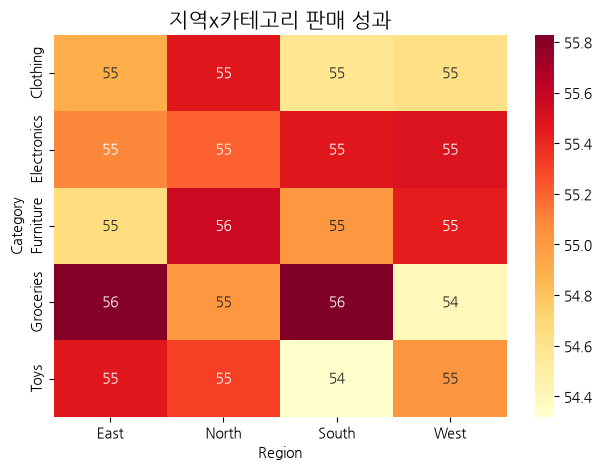

In [11]:
sns.heatmap(pivot,annot = True,cmap="YlOrRd")

plt.title("지역x카테고리 판매 성과", fontsize = 15)
plt.tight_layout()
plt.show()

## 카테고리별 주문 수량 비교

In [12]:
mf = df.groupby('Category').agg(TotalOrdered = ('Units Ordered','sum')).reset_index().sort_values('TotalOrdered',ascending = False)
mf

,Category,TotalOrdered
2,Furniture,1617699
0,Clothing,1614885
4,Toys,1610222
3,Groceries,1606188
1,Electronics,1592333


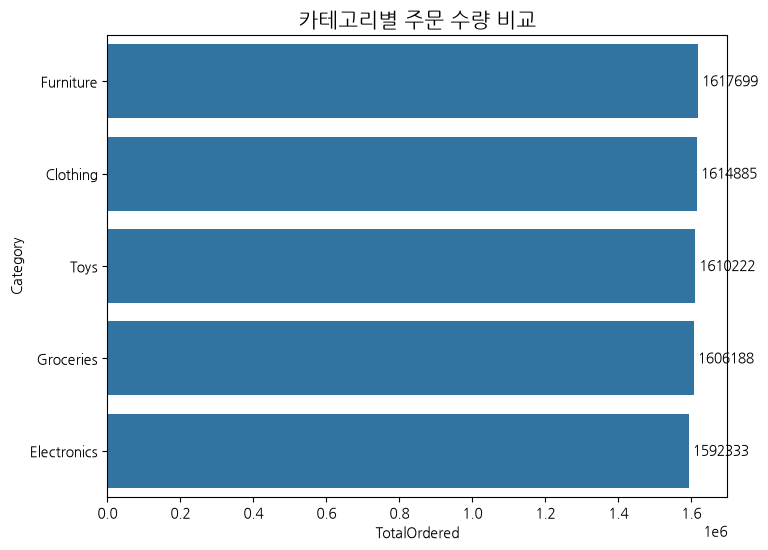

In [13]:
plt.figure(figsize = (8,6))
ax = sns.barplot(data = mf, x = 'TotalOrdered', y = 'Category')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title("카테고리별 주문 수량 비교", fontsize = 15)

plt.show()

## 머신러닝 회귀

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

In [15]:
# 예측에 사용할 변수
features = [
    'Inventory Level', 
    'Price', 
    'Discount', 
    'Units Ordered', 
    'Category', 
    'Region'
]

x = df[features].copy() 
y = df['Units Sold']

In [16]:
# 범주형 / 수치형 변수 구분
categorical_features = ['Category', 'Region']
numeric_features = [
    'Inventory Level',
    'Price',
    'Discount',
    'Units Ordered'
]

In [17]:
# 범주형 변수는 숫자로 변환하고, 결측값은 보완
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(),categorical_features),
    ('num',SimpleImputer(strategy = 'median'),numeric_features)
])

In [18]:
# 전처리 + 회귀 모델
model = make_pipeline(
    preprocessor,
    LinearRegression()
)

In [19]:
# 학습 데이터와 테스트 데이터 분리
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size = 0.2, random_state = 42 
)

In [20]:
# RandomForest모델 학습 및 예측
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [21]:
# 성능 평가
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', mean_squared_error(y_test, y_pred) ** 0.5)
print('R²:', r2_score(y_test, y_pred))

MAE: 68.91025432909696
RMSE: 88.04222873900501
R²: 0.34529952084699944


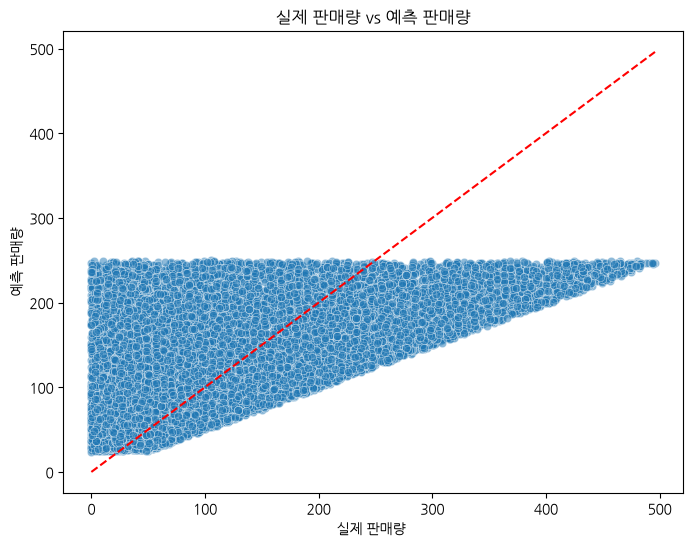

In [22]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)

# 실제값과 예측값이 같은 기준선
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--')

plt.xlabel('실제 판매량 ')
plt.ylabel('예측 판매량')
plt.title('실제 판매량 vs 예측 판매량')
plt.show()